# Phase 2: Exploratory Data Analysis & Degradation Physics (NASA C-MAPSS FD001)

**Course:** ES 335: Machine Learning (2026)  
**Scope:** Strictly restricted to the **80 Development Engines** (`16,340` operating cycles). The 20 held-out test engines remain sealed until Phase 5.

---

### Key Questions Investigated in Phase 2
1. **Sensor & Setting Screening:** Which of the 3 operating settings and 21 sensors carry real physical degradation signal vs. zero/near-zero variance?
2. **The Fixed-Schedule Dilemma:** Why does a fixed maintenance interval ($K$ cycles) inevitably force a costly trade-off between catastrophic in-service failures and wasted remaining engine life?
3. **Forward Time vs. Failure-Aligned Trajectories:** Why does aligning engines backward by *cycles before failure* ($t - T_{\text{fail}}$) collapse heterogeneous engines onto a universal degradation trajectory starting $\sim 125$ cycles prior to failure?
4. **Multivariate Correlation & PCA Health Index:** Can an unsupervised 1D Principal Component Health Index capture multi-sensor compressor degradation without using RUL labels?

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.append(str(REPO_ROOT))

from src.data import load_development_data
from src.eda import (
    screen_sensors_and_settings,
    analyze_fixed_schedule_tradeoff,
    fit_pca_health_index,
)

dev_df = load_development_data(rul_cap=125, alarm_w=30)
print(f'Loaded {dev_df["unit_id"].nunique()} development engines ({len(dev_df):,} total operating cycles).')

Loaded 80 development engines (16,340 total operating cycles).


## 1. Sensor & Operating Setting Variance Screening
We inspect standard deviation, dynamic range, and Pearson correlation with capped and uncapped RUL across all 24 telemetry channels on the 80 development engines.

In [2]:
sensor_summary_df, retained_sensors, dropped_channels = screen_sensors_and_settings(dev_df)
print('Retained Informative Sensors (14):', retained_sensors)
print('Dropped Constant/Uninformative Channels (10):', dropped_channels)
sensor_summary_df[['channel', 'physical_description', 'mean', 'std', 'range', 'corr_rul_capped', 'status']]

Retained Informative Sensors (14): ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Dropped Constant/Uninformative Channels (10): ['op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


,channel,physical_description,mean,std,range,corr_rul_capped,status
0,op_setting_1,Altitude (Sea Level ~0 ft),-0.0000,0.002190,0.0169,-0.0049,Dropped (Fixed Sea-Level Setting)
1,op_setting_2,Mach Number (~0.0),0.0000,0.000293,0.0012,-0.0030,Dropped (Fixed Sea-Level Setting)
2,op_setting_3,Throttle Resolver Angle (100%),100.0000,0.000000,0.0000,0.0000,Dropped (Fixed Sea-Level Setting)
3,sensor_1,Total temperature at fan inlet (°R),518.6700,0.000000,0.0000,0.0000,Dropped (Exactly Constant)
4,sensor_2,Total temperature at LPC outlet (°R),642.6883,0.499149,3.2800,-0.6746,Retained (Rising with wear)
5,sensor_3,Total temperature at HPC outlet (°R),1590.6190,6.110832,45.8700,-0.6511,Retained (Rising with wear)
6,sensor_4,Total temperature at LPT outlet (°R),1409.0616,8.980629,56.7100,-0.7533,Retained (Rising with wear)
7,sensor_5,Pressure at fan inlet (psia),14.6200,0.000000,0.0000,0.0000,Dropped (Exactly Constant)
8,sensor_6,Total pressure in bypass-duct (psia),21.6098,0.001377,0.0100,-0.1069,Dropped (Near-Constant / Uninformative)
9,sensor_7,Total pressure at HPC outlet (psia),553.3553,0.883157,6.2100,0.7264,Retained (Falling with wear)


## 2. Fleet Lifetime Distribution & Fixed-Schedule Replacement Trade-Off
Development engine lifetimes span from **128 to 362 cycles** (median = 199.0, mean = 204.25, std = 45.63). A static replacement schedule at cycle $K$ must either replace at $K=128$ (wasting 37.3% of fleet life) or accept high failure rates.

,replacement_cycle_K,engines_failed,failure_rate_pct,mean_wasted_cycles_per_engine,mean_wasted_cycles_survivors,pct_total_fleet_life_wasted
1,128,1,1.25,76.25,77.22,37.33
3,140,4,5.00,64.54,67.93,31.60
5,160,14,17.50,46.24,56.05,22.64
8,180,25,31.25,31.10,45.24,15.23
10,199,42,52.50,19.51,41.08,9.55
13,220,58,72.50,11.78,42.82,5.76
16,250,67,83.75,5.49,33.77,2.69


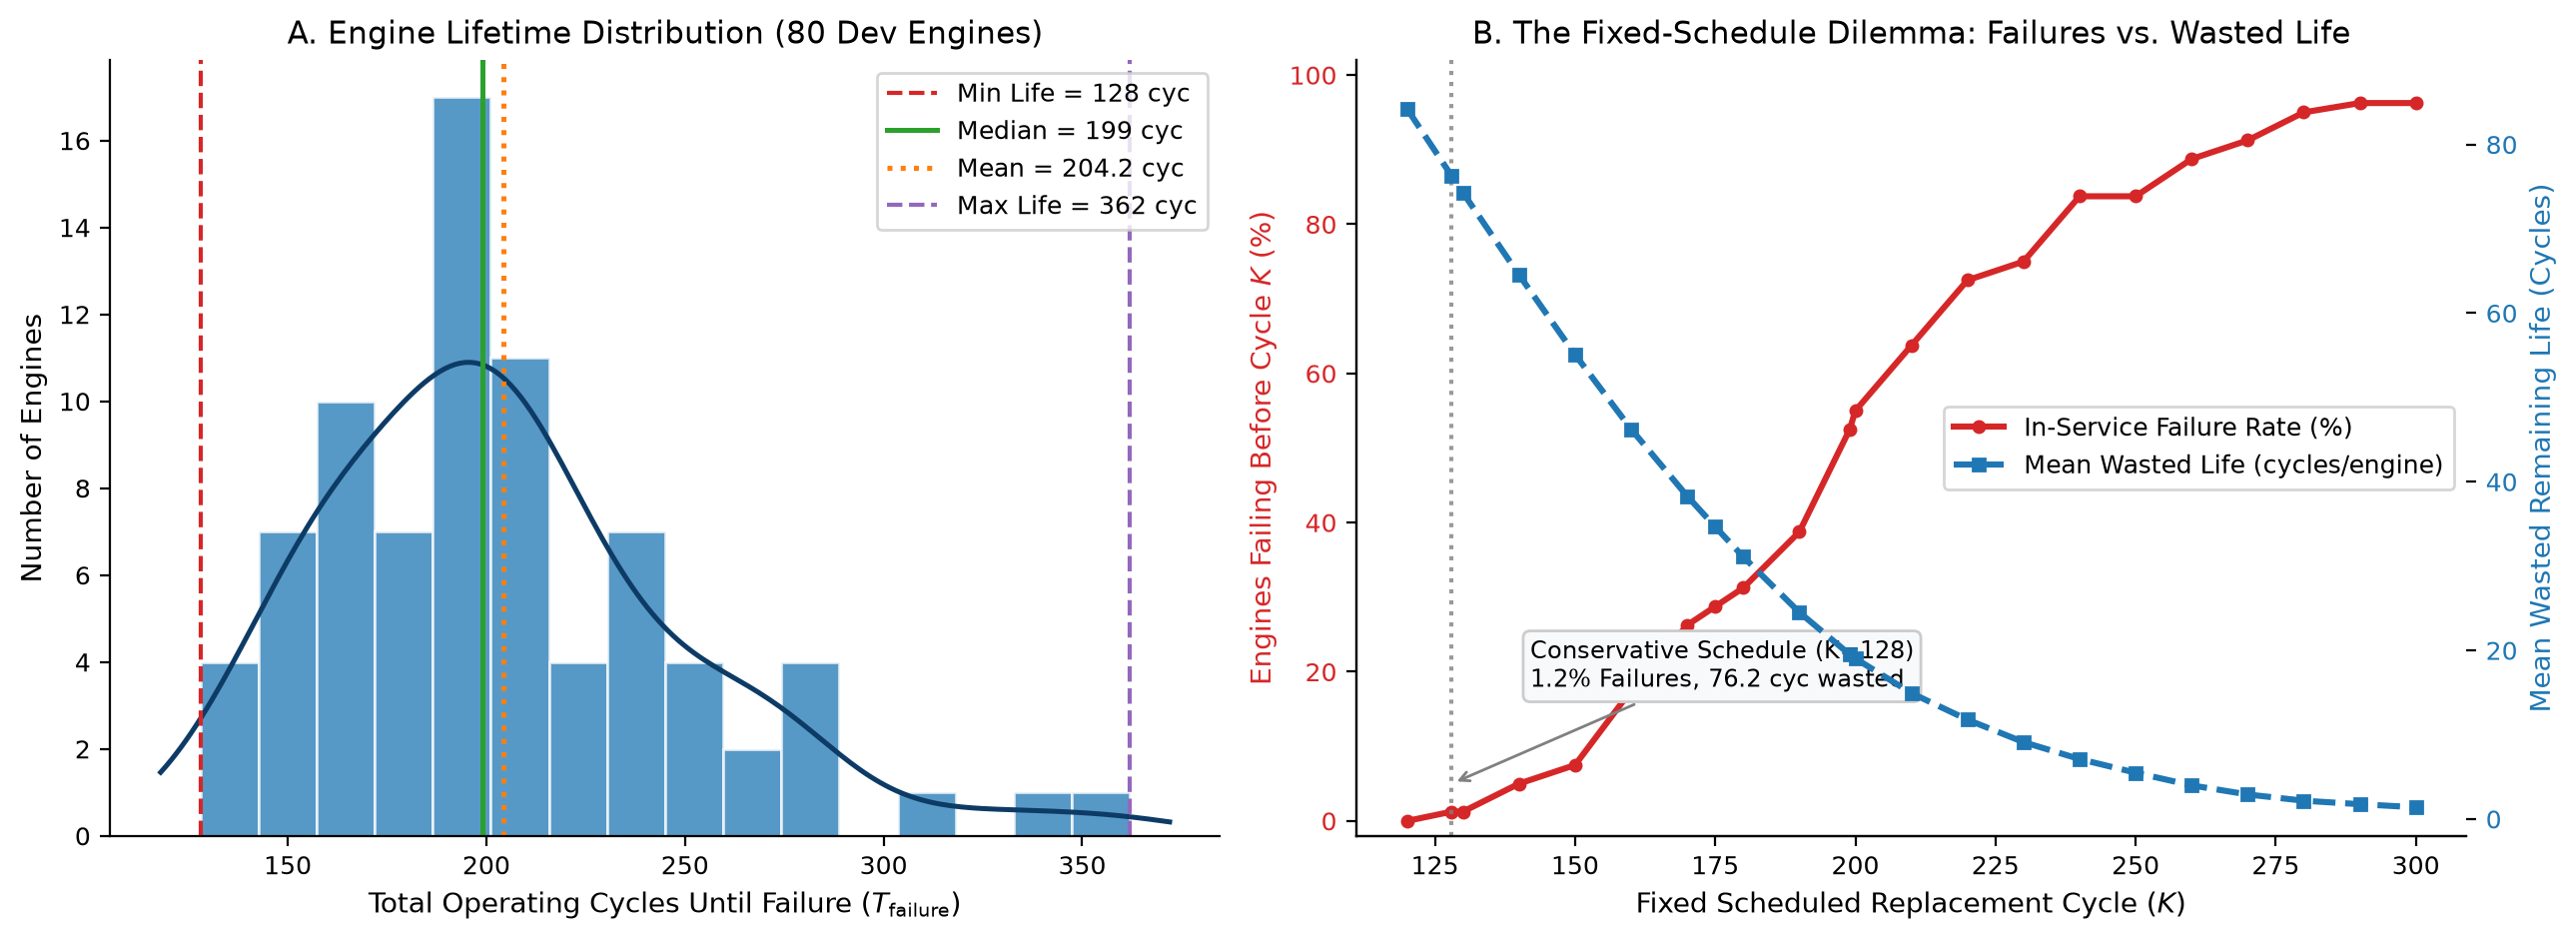

In [3]:
tradeoff_df = analyze_fixed_schedule_tradeoff(dev_df)
display(tradeoff_df[tradeoff_df['replacement_cycle_K'].isin([128, 140, 160, 180, 199, 220, 250])])
display(Image(filename=str(REPO_ROOT / 'results/figures/engine_lifetime_distribution.png')))

## 3. Degradation Trajectory Alignment ($t$ vs. $-\text{RUL}$)
Aligning trajectories backward from failure ($t - T_{\text{failure}}$) demonstrates why **piecewise-linear RUL capping at 125 cycles** reflects physical reality: sensor drift is flat earlier than 125 cycles before failure, then accelerates non-linearly into the $w=30$ alarm window.

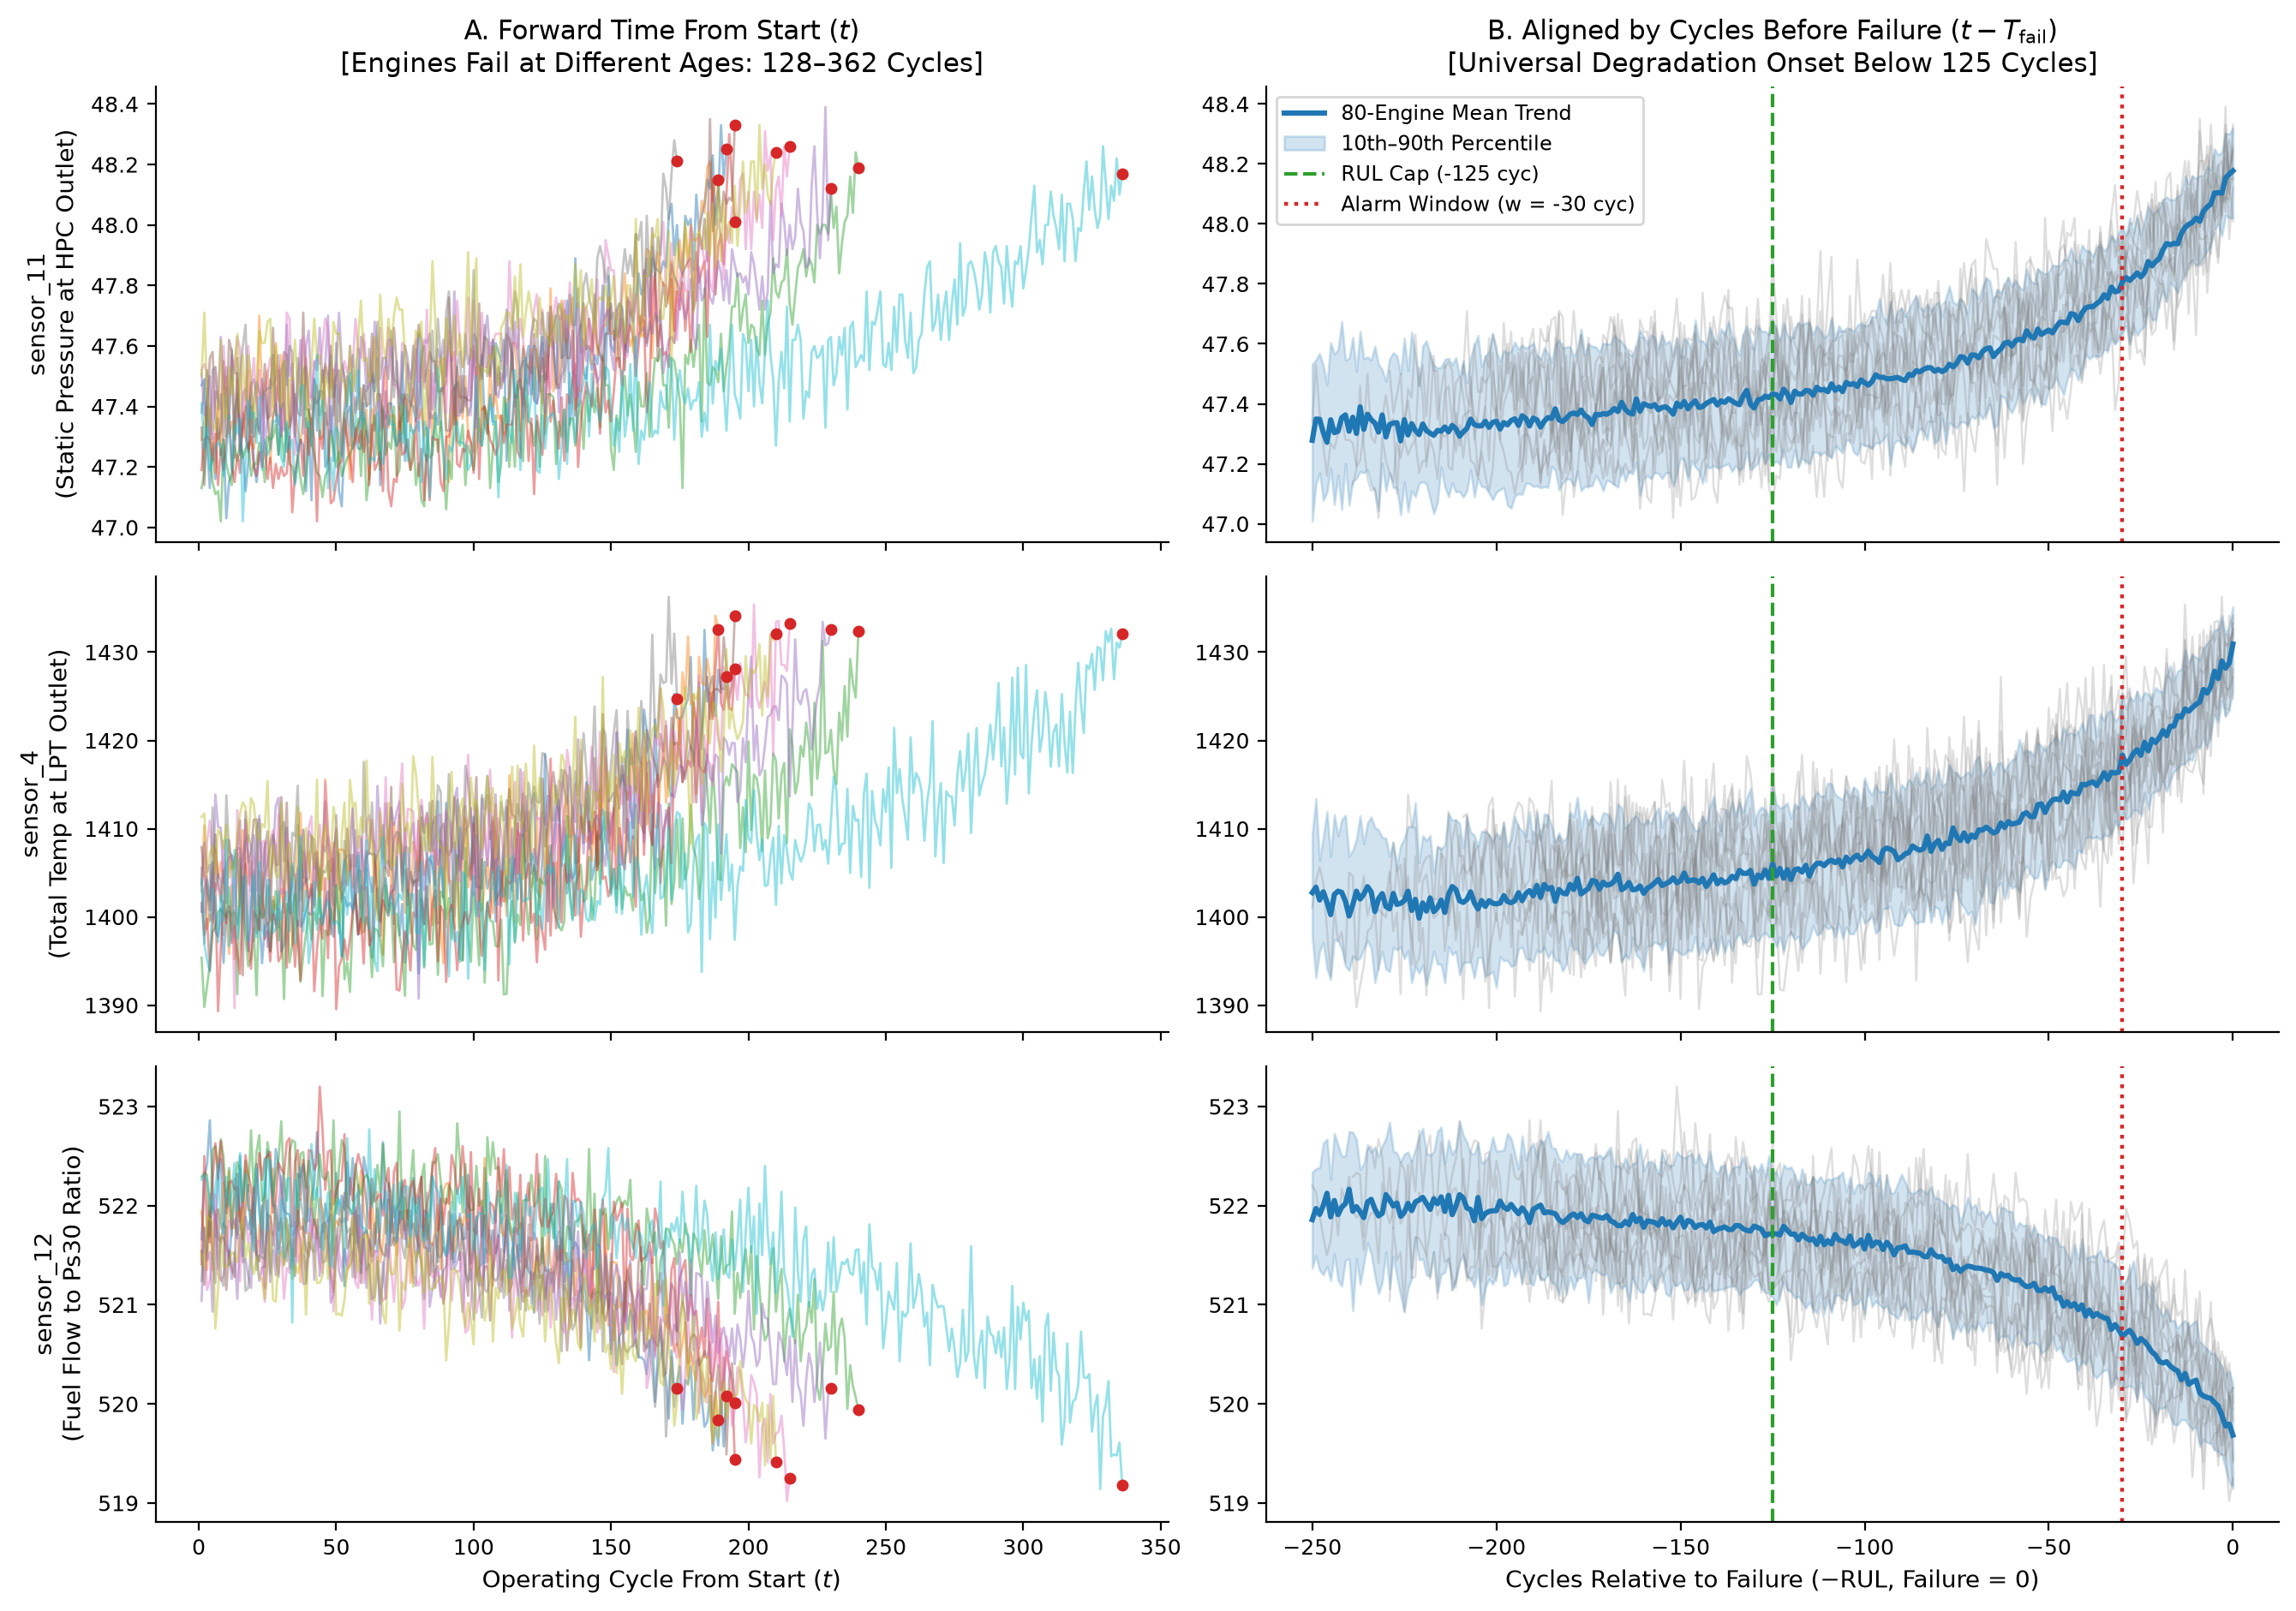

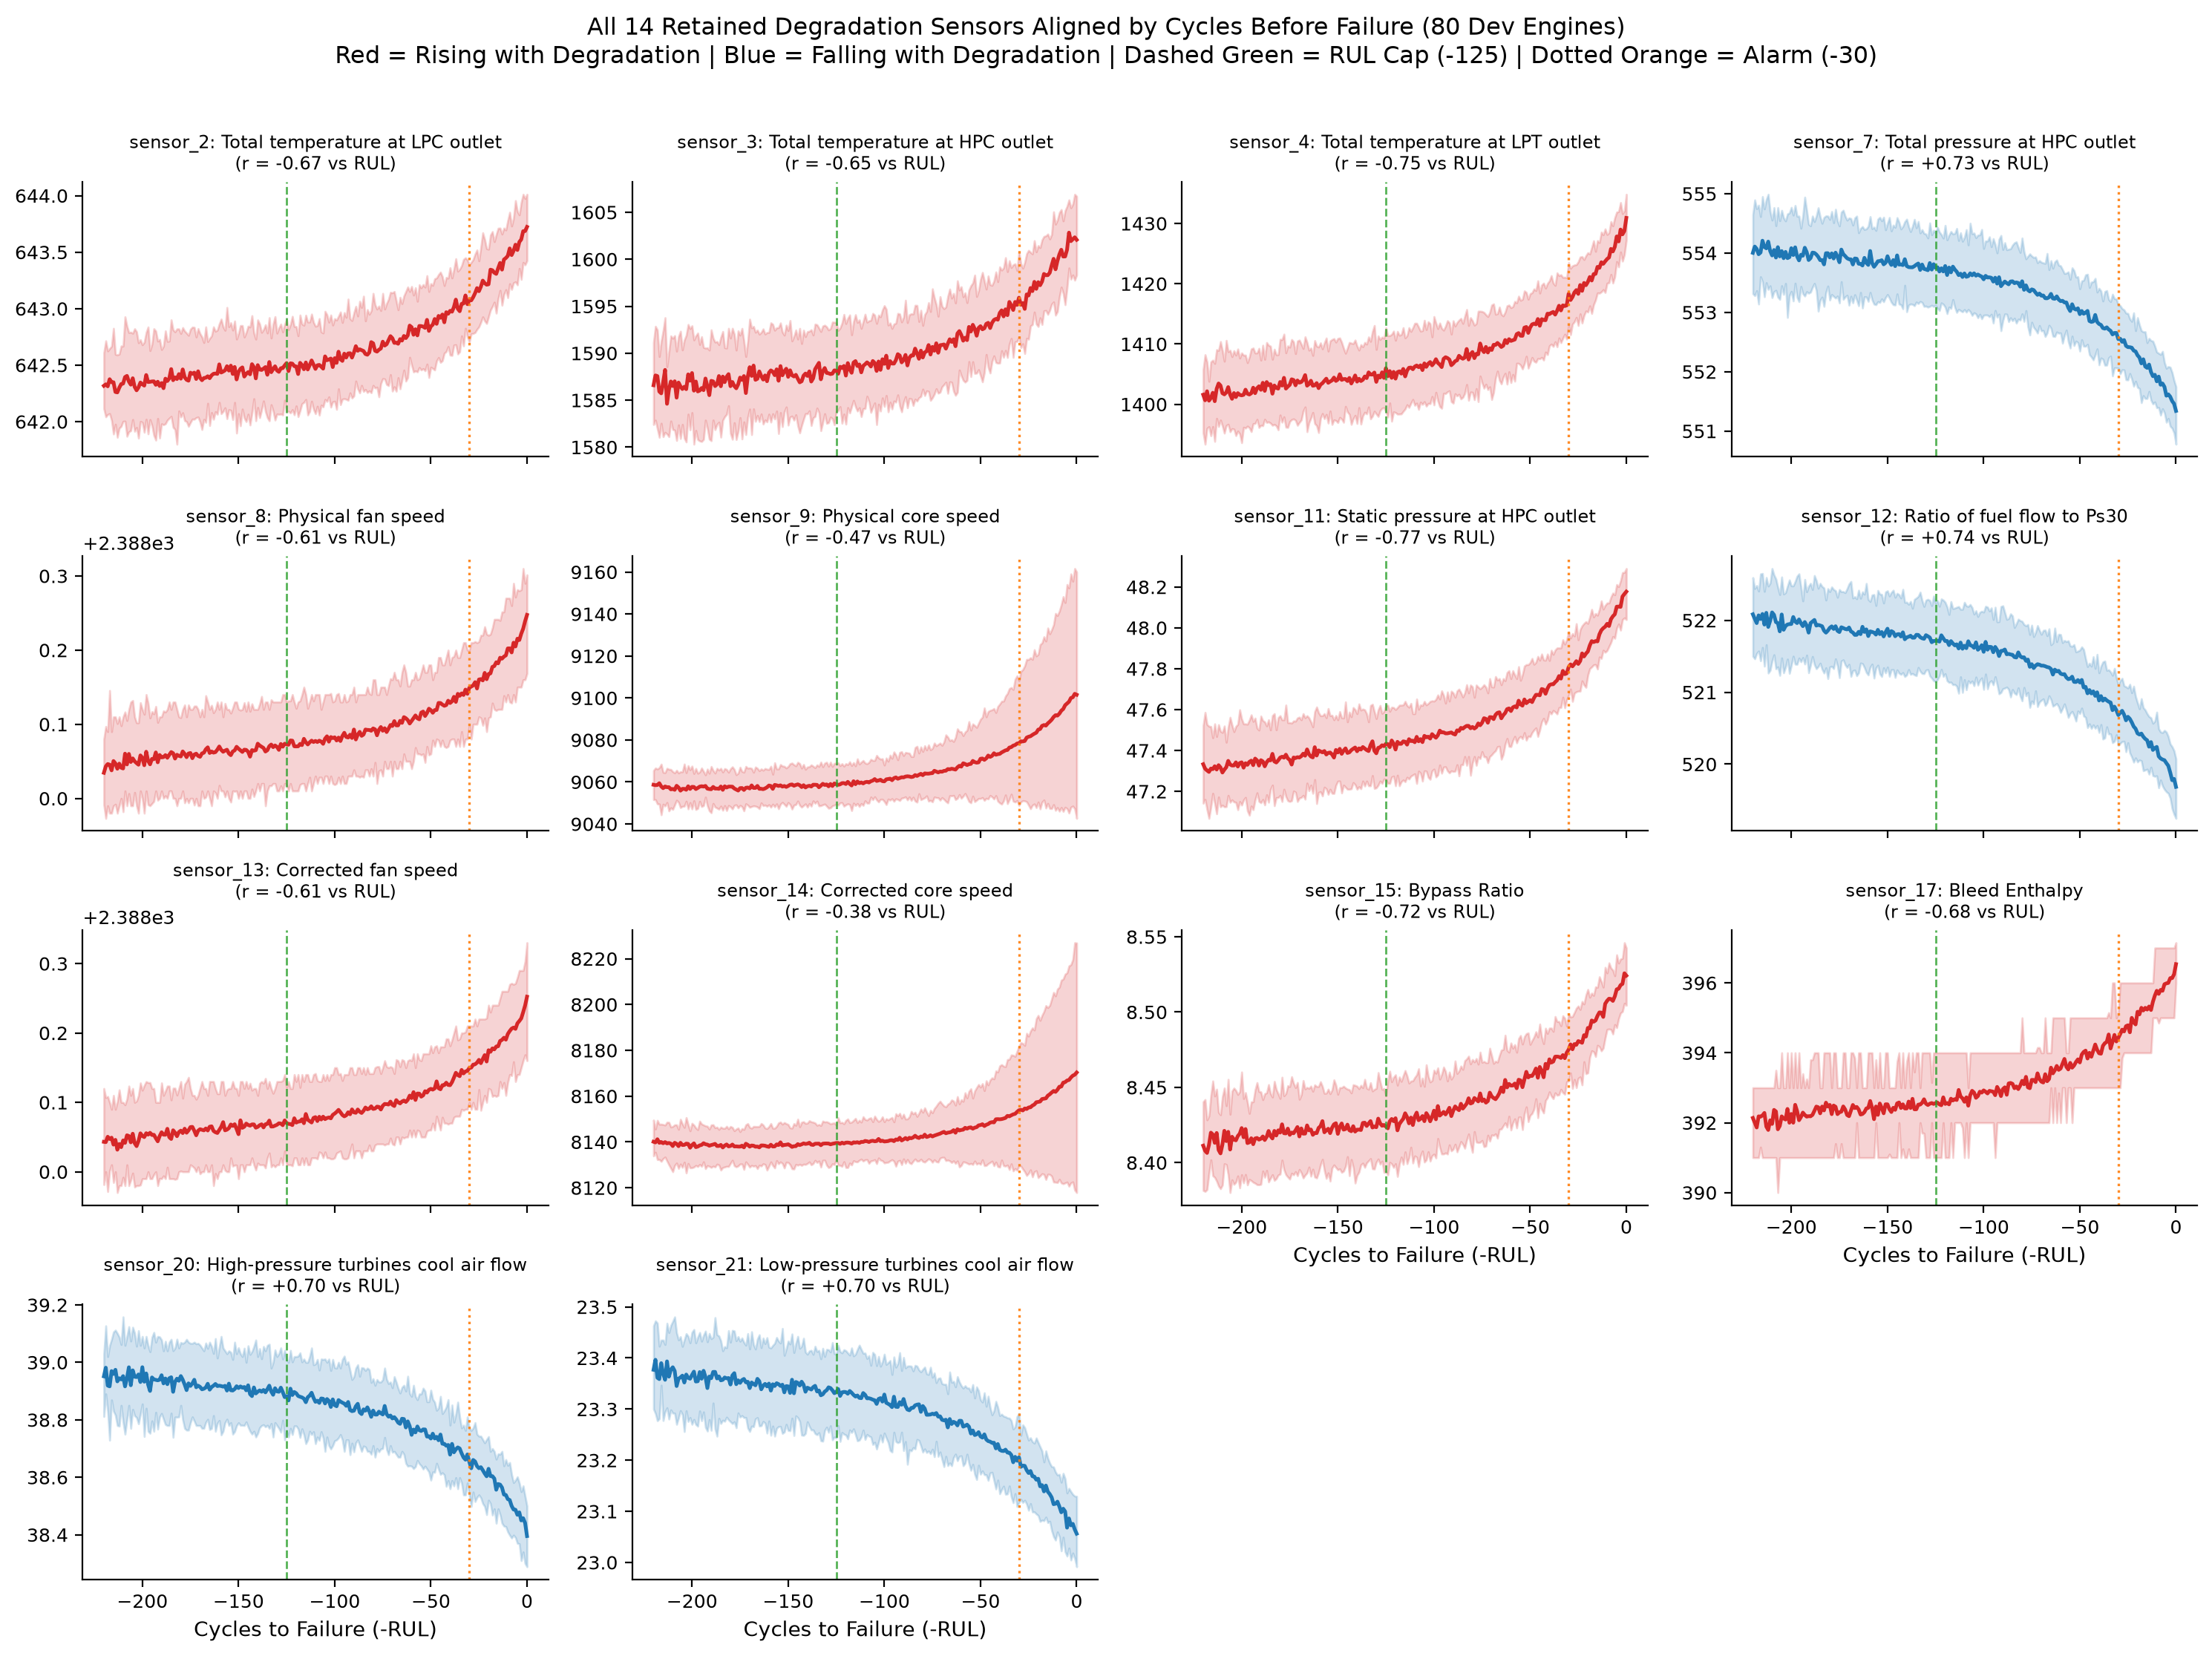

In [4]:
display(Image(filename=str(REPO_ROOT / 'results/figures/sensor_trajectories_aligned.png')))
display(Image(filename=str(REPO_ROOT / 'results/figures/all_14_retained_sensors_trends.png')))

## 4. Sensor Correlation Structure & Unsupervised PCA Health Index
Fitting a 1D Principal Component Analysis (PCA) model on the standardized 14 retained sensors extracts a single composite health index that explains **>65% of total multi-sensor variance** and correlates strongly with RUL without using target labels.

PCA Summary: {'explained_variance_ratio_pc1': 0.6409, 'explained_variance_ratio_pc2': 0.15, 'explained_variance_ratio_pc3': 0.0299, 'cumulative_top3_variance': 0.8207, 'corr_pc1_with_rul_capped': 0.8245, 'corr_pc1_with_rul_uncapped': 0.7382, 'pc1_sensor_loadings': {'sensor_2': -0.273, 'sensor_3': -0.2597, 'sensor_4': -0.3015, 'sensor_7': 0.2981, 'sensor_8': -0.2822, 'sensor_9': -0.1044, 'sensor_11': -0.3095, 'sensor_12': 0.3046, 'sensor_13': -0.2818, 'sensor_14': -0.0656, 'sensor_15': -0.2874, 'sensor_17': -0.2688, 'sensor_20': 0.2826, 'sensor_21': 0.2841}}


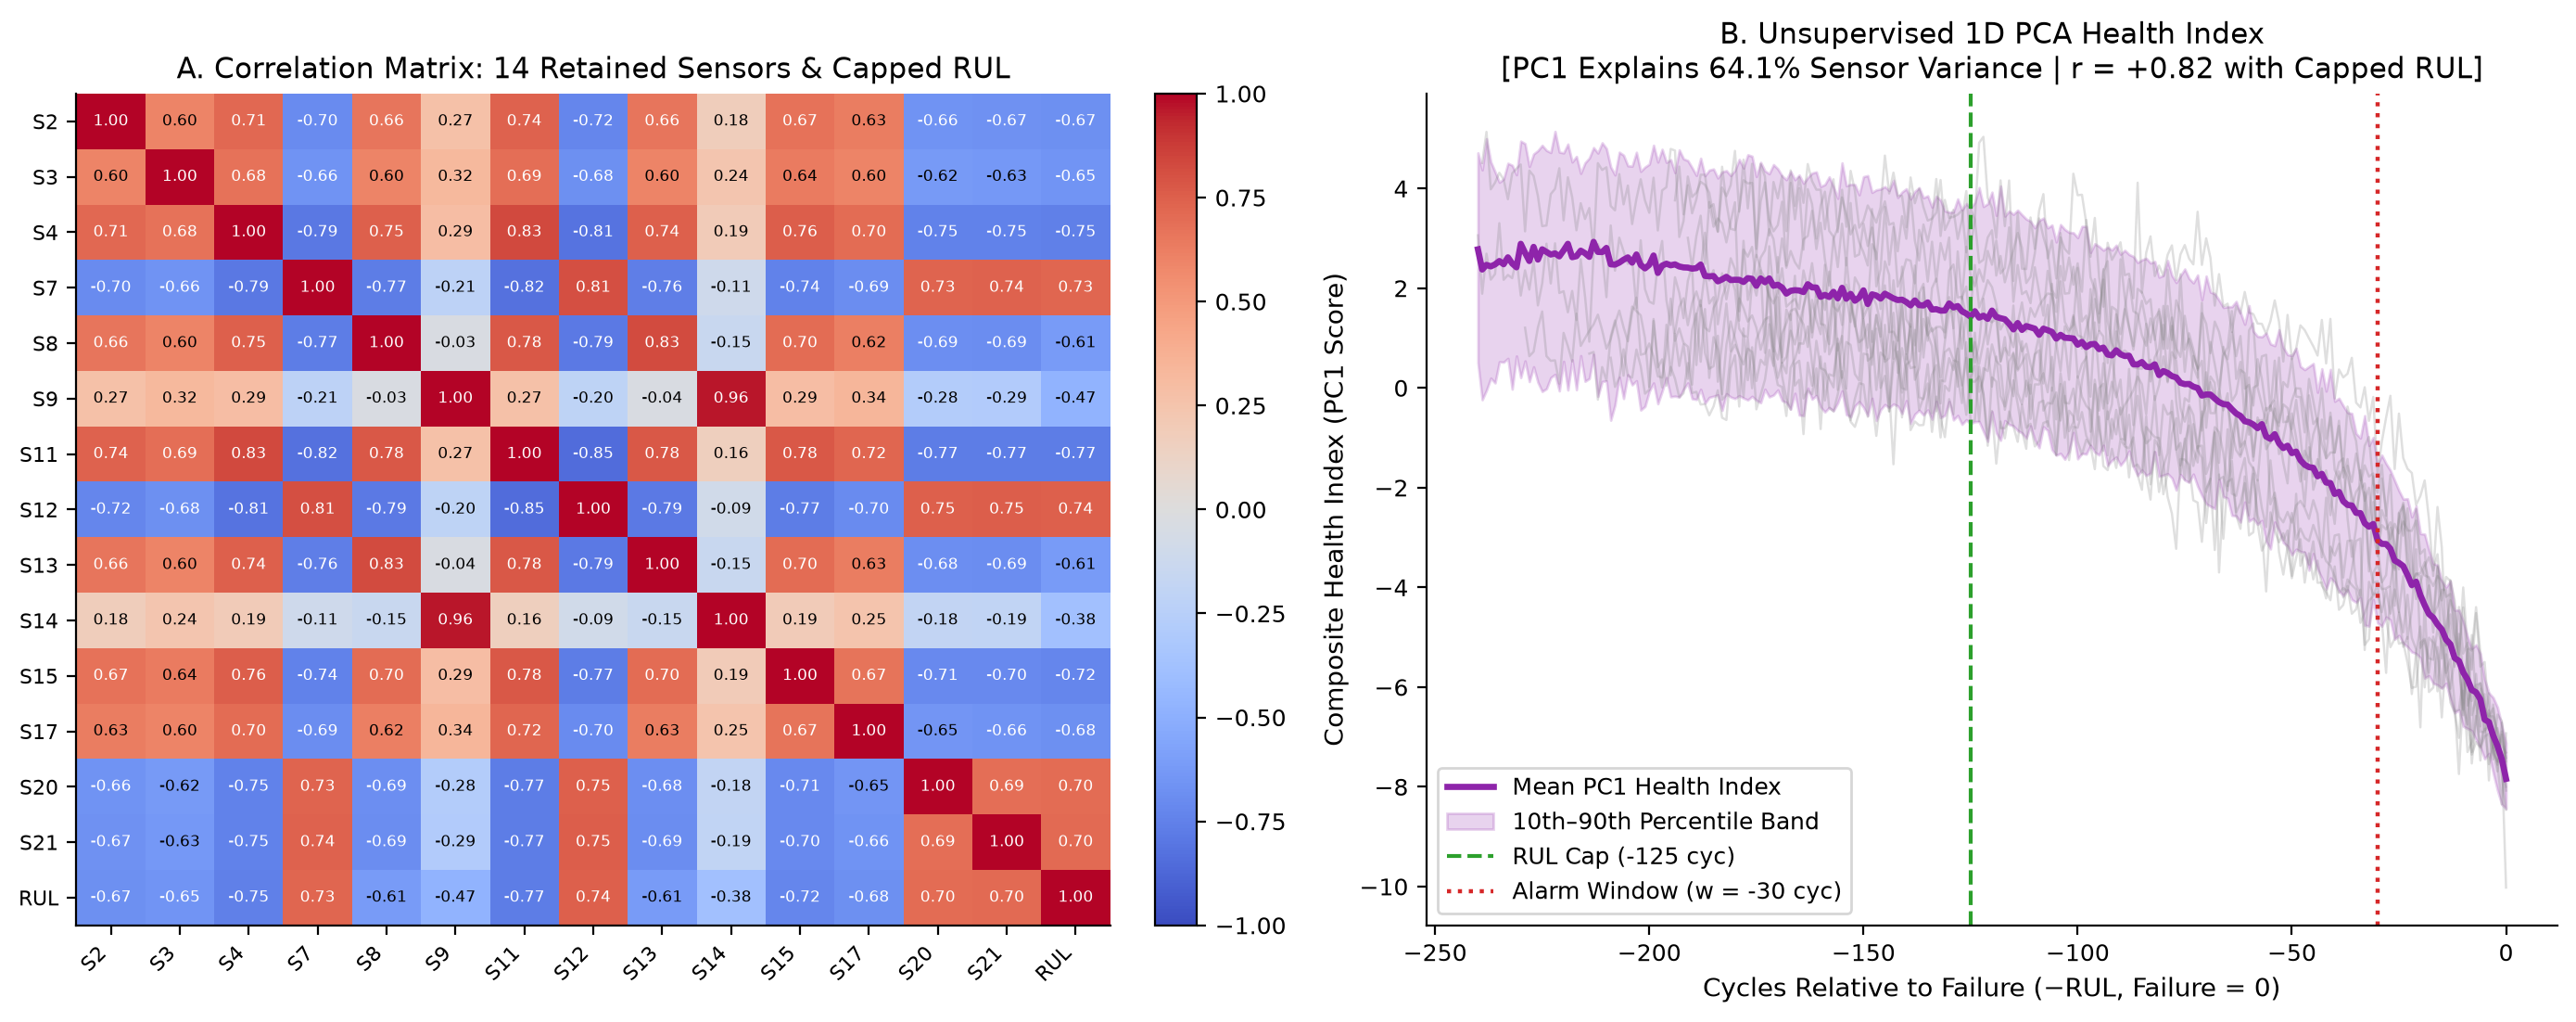

In [5]:
pca_df, pca_info = fit_pca_health_index(dev_df, retained_sensors)
print('PCA Summary:', pca_info)
display(Image(filename=str(REPO_ROOT / 'results/figures/sensor_correlation_and_pca_health_index.png')))